# Book Recommender System on a Medallion Data Lake

**Name:** Lavesh Jadon
**Roll No.:** MSD25023

In this notebook I take the Book-Crossing dataset from raw files all the way to a working book recommender.
The data moves through three layers before it reaches the model:

| Layer | What it holds |
|---|---|
| **Bronze** | the raw files, untouched, plus an ingestion timestamp |
| **Silver** | cleaned and filtered tables |
| **Gold** | model-ready data: sparse rating matrix, lookup table, aggregates |

The recommender itself is **item-based collaborative filtering** using cosine similarity between books.

## 0. Libraries

In [1]:
import os
import re
import html
import zipfile
import urllib.request
from collections import defaultdict
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.max_colwidth", 70)

## 1. Data lake setup + Bronze layer

First I grab the zip straight from the source link given in the assignment.

In [2]:
DATA_URL = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
ZIP_FILE = "book-crossings.zip"
RAW_DIR = "raw_data"

# Downloading only once - re-running the notebook shouldn't fetch 26 MB again.
# The CDN refuses Python's default user agent (gives HTTP 403), so I pretend to be a browser.
if not os.path.exists(ZIP_FILE):
    request = urllib.request.Request(DATA_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request) as response, open(ZIP_FILE, "wb") as out:
        out.write(response.read())

print(f"{ZIP_FILE}: {os.path.getsize(ZIP_FILE) / 1e6:.1f} MB")

with zipfile.ZipFile(ZIP_FILE) as archive:
    archive.extractall(RAW_DIR)
print("Extracted:", os.listdir(RAW_DIR))

book-crossings.zip: 26.1 MB


Extracted: ['BX-Book-Ratings.csv', 'BX-Books.csv', 'BX-Users.csv']


Now the three folders of the lake.

In [3]:
LAYERS = ["bronze", "silver", "gold"]
for layer in LAYERS:
    os.makedirs(layer, exist_ok=True)

print([f for f in os.listdir(".") if f in LAYERS])

['bronze', 'gold', 'silver']


Reading the raw CSVs. A few things I had to handle here:
- the separator is `;` and not a comma
- the files are in `latin-1`, reading them as UTF-8 throws decode errors
- some book titles contain escaped quotes (`\"`), so `escapechar` is needed or rows get broken
- I read everything as `str` on purpose, Bronze should be a 1:1 copy of the source

In [4]:
def read_raw(filename, **extra):
    return pd.read_csv(os.path.join(RAW_DIR, filename), sep=";", encoding="latin-1", dtype=str, **extra)

raw = {
    "users":   read_raw("BX-Users.csv"),
    "books":   read_raw("BX-Books.csv", escapechar="\\"),
    "ratings": read_raw("BX-Book-Ratings.csv"),
}

for name, df in raw.items():
    print(f"{name:8s} {df.shape}")

users    (278858, 3)
books    (271379, 8)
ratings  (1149780, 3)


Stamp each table with the load time and dump it to `bronze/` as Parquet. No cleaning at all at this stage.

In [5]:
loaded_at = datetime.now()

for name, df in raw.items():
    df["ingestion_timestamp"] = loaded_at
    df.to_parquet(f"bronze/{name}.parquet", index=False)

print("bronze/ ->", sorted(os.listdir("bronze")))

bronze/ -> ['books.parquet', 'ratings.parquet', 'users.parquet']


## 2. Exploring the Bronze data

I read the tables back from Bronze (not from memory) so the EDA is done on what is actually stored in the lake.

In [6]:
users_b = pd.read_parquet("bronze/users.parquet")
books_b = pd.read_parquet("bronze/books.parquet")
ratings_b = pd.read_parquet("bronze/ratings.parquet")

### 2.1 Shape, types and missing values

In [7]:
for name, df in [("users", users_b), ("books", books_b), ("ratings", ratings_b)]:
    print(f"--- {name}: {df.shape[0]:,} rows x {df.shape[1]} cols ---")
    summary = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()})
    print(summary, "\n")

--- users: 278,858 rows x 4 cols ---
                              dtype  missing
User-ID                      object        0
Location                     object        0
Age                          object   110762
ingestion_timestamp  datetime64[us]        0 

--- books: 271,379 rows x 9 cols ---
                              dtype  missing
ISBN                         object        0
Book-Title                   object        0
Book-Author                  object        2
Year-Of-Publication          object        0
Publisher                    object        2
Image-URL-S                  object        0
Image-URL-M                  object        0
Image-URL-L                  object        0
ingestion_timestamp  datetime64[us]        0 

--- ratings: 1,149,780 rows x 4 cols ---


                              dtype  missing
User-ID                      object        0
ISBN                         object        0
Book-Rating                  object        0
ingestion_timestamp  datetime64[us]        0 



**What I see:** every column is a string (as expected for Bronze). `Age` is missing for 110,762 users, and books have 2 missing authors and 2 missing publishers.
**Plan for Silver:** cast columns to proper numeric types and fill the missing ages with the median.

### 2.2 How are the ratings distributed?

Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

Zero ratings: 716,109  (62.3% of everything)


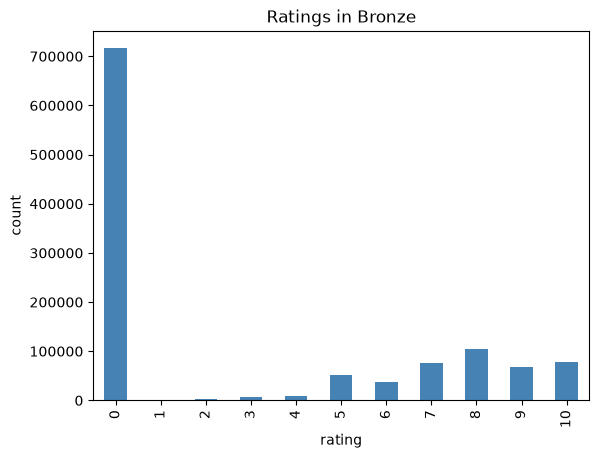

In [8]:
rating_values = ratings_b["Book-Rating"].astype(int)
dist = rating_values.value_counts().sort_index()
print(dist)

zeros = (rating_values == 0).sum()
print(f"\nZero ratings: {zeros:,}  ({zeros / len(rating_values):.1%} of everything)")

dist.plot.bar(title="Ratings in Bronze", xlabel="rating", ylabel="count", color="steelblue")
plt.show()

**What I see:** 716,109 ratings (roughly 62%) are 0. In this dataset 0 means the user interacted with the book but didn't actually rate it.
**Plan for Silver:** drop all zeros and only keep the explicit 1–10 ratings.

### 2.3 User ages

count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64

under 5  : 882
over 100 : 366


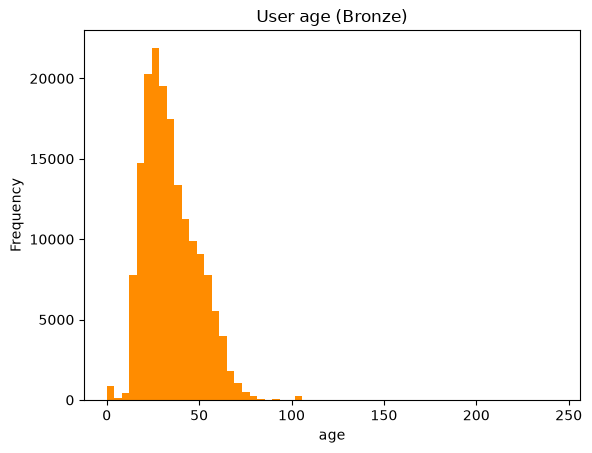

In [9]:
age_num = pd.to_numeric(users_b["Age"], errors="coerce")
print(age_num.describe())
print("\nunder 5  :", (age_num < 5).sum())
print("over 100 :", (age_num > 100).sum())

age_num.plot.hist(bins=60, title="User age (Bronze)", color="darkorange")
plt.xlabel("age")
plt.show()

**What I see:** there are clearly fake ages - 882 users under 5 and 366 over 100, with a maximum of 244.
**Plan for Silver:** turn anything outside 5–100 into null and then fill nulls with the median.

### 2.4 Publication years

count    271379.000000
mean       1959.756050
std         258.011363
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64

year == 0         : 4619
year in future    : 11
year 1..1899      : 4


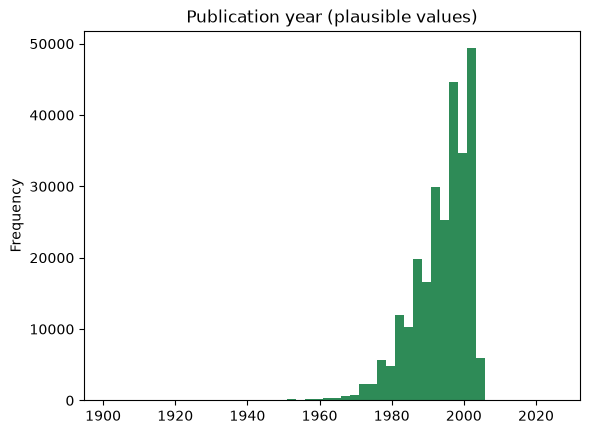

In [10]:
year_num = pd.to_numeric(books_b["Year-Of-Publication"], errors="coerce")
current_year = datetime.now().year

print(year_num.describe())
print("\nyear == 0         :", (year_num == 0).sum())
print("year in future    :", (year_num > current_year).sum())
print("year 1..1899      :", year_num.between(1, 1899).sum())

year_num[year_num.between(1901, current_year)].plot.hist(bins=50, title="Publication year (plausible values)", color="seagreen")
plt.show()

**What I see:** 4,619 books have year 0 and 11 books are "published" in the future (one even in 2050).
**Plan for Silver:** set year 0 and future years to null.

### 2.5 Ratings per user and per book

In [11]:
by_user = ratings_b["User-ID"].value_counts()
by_book = ratings_b["ISBN"].value_counts()

for label, counts in [("user", by_user), ("book", by_book)]:
    print(f"ratings per {label}:")
    print(counts.describe().round(2))
    print(f"share with <= 5 ratings: {(counts <= 5).mean():.1%}\n")

ratings per user:
count    105283.00
mean         10.92
std          90.56
min           1.00
25%           1.00
50%           1.00
75%           4.00
max       13602.00
Name: count, dtype: float64
share with <= 5 ratings: 81.3%

ratings per book:
count    340556.00
mean          3.38
std          12.44
min           1.00
25%           1.00
50%           1.00
75%           2.00
max        2502.00
Name: count, dtype: float64
share with <= 5 ratings: 89.8%



**What I see:** it is a long tail - the median user and median book both have just **1** rating, and ~81% of users / ~90% of books have 5 or less.
**Plan for Silver:** filter out users and books with too few ratings (threshold picked in step 3.9).

### 2.6 Sparsity of the user-book matrix

In [12]:
n_u = ratings_b["User-ID"].nunique()
n_b = ratings_b["ISBN"].nunique()
cells_total = n_u * n_b
density = len(ratings_b) / cells_total

print(f"users            : {n_u:,}")
print(f"books            : {n_b:,}")
print(f"possible pairs   : {cells_total:,}")
print(f"actual ratings   : {len(ratings_b):,}")
print(f"filled           : {density:.4%}")
print(f"empty            : {1 - density:.4%}")

users            : 105,283
books            : 340,556
possible pairs   : 35,854,757,348
actual ratings   : 1,149,780
filled           : 0.0032%
empty            : 99.9968%


**What I see:** only about 0.003% of user-book pairs have a rating - the matrix is basically empty.
**Plan for Silver/Gold:** store it as a scipy sparse matrix; the filtering step will also make it denser.

## 3. Cleaning → Silver layer

I start again from the Bronze files and throw away the timestamp column since it was only lineage info.

In [13]:
users = pd.read_parquet("bronze/users.parquet").drop(columns="ingestion_timestamp")
books = pd.read_parquet("bronze/books.parquet").drop(columns="ingestion_timestamp")
ratings = pd.read_parquet("bronze/ratings.parquet").drop(columns="ingestion_timestamp")

### 3.1 Friendlier column names + proper types

In [14]:
users.columns = ["user_id", "location", "age"]
books = books.rename(columns={"ISBN": "isbn", "Book-Title": "title", "Book-Author": "author",
                              "Year-Of-Publication": "year", "Publisher": "publisher"})
ratings.columns = ["user_id", "isbn", "rating"]

users["user_id"] = users["user_id"].astype(int)
users["age"] = pd.to_numeric(users["age"], errors="coerce")
books["year"] = pd.to_numeric(books["year"], errors="coerce")
ratings = ratings.astype({"user_id": int, "rating": int})

# ISBNs sometimes come with stray spaces or a lowercase 'x' at the end,
# normalising them now means duplicates and joins work properly later
for df in (books, ratings):
    df["isbn"] = df["isbn"].str.strip().str.upper()

### 3.2 Duplicates

In [15]:
sizes_before = (len(users), len(books), len(ratings))

users = users.drop_duplicates("user_id")
books = books.drop_duplicates("isbn")
ratings = ratings.drop_duplicates(["user_id", "isbn"])

print("users / books / ratings before:", sizes_before)
print("users / books / ratings after :", (len(users), len(books), len(ratings)))

users / books / ratings before: (278858, 271379, 1149780)
users / books / ratings after : (278858, 271064, 1149780)


### 3.3 Dropping the 0 ratings

In [16]:
n_before = len(ratings)
ratings = ratings[ratings["rating"].between(1, 10)]
print(f"{n_before:,} -> {len(ratings):,} ratings (range now {ratings.rating.min()}-{ratings.rating.max()})")

1,149,780 -> 433,671 ratings (range now 1-10)


### 3.4 Fixing ages

In [17]:
# anything below 5 or above 100 is not a real age
users["age"] = users["age"].where(users["age"].between(5, 100))

age_median = users["age"].median()
users["age"] = users["age"].fillna(age_median).astype(int)

print("median age used for filling:", age_median)
print("nulls left in age:", users["age"].isna().sum())

median age used for filling: 32.0
nulls left in age: 0


### 3.5 Location → city / state / country

The location is written like `"nyc, new york, usa"`. I take the first piece as city, the last as country,
and the second one as state (only if there are at least 3 pieces).

In [18]:
pieces = users["location"].str.split(",").apply(lambda parts: [p.strip() for p in parts])

users["city"] = pieces.str[0]
users["country"] = pieces.str[-1]
users["state"] = pieces.apply(lambda parts: parts[1] if len(parts) >= 3 else "")

users = users.drop(columns="location")
users[["city", "state", "country"]] = users[["city", "state", "country"]].replace("", np.nan)

users.head()

,user_id,age,city,country,state
0,1,32,nyc,usa,new york
1,2,18,stockton,usa,california
2,3,32,moscow,russia,yukon territory
3,4,17,porto,portugal,v.n.gaia
4,5,32,farnborough,united kingdom,hants


### 3.6 Fixing publication years

In [19]:
current_year = datetime.now().year
invalid_year = (books["year"] == 0) | (books["year"] > current_year)
print("invalid years set to null:", invalid_year.sum())

books.loc[invalid_year, "year"] = np.nan
books["year"] = books["year"].astype("Int64")   # nullable int, so the NaNs don't force floats

invalid years set to null: 4623


### 3.7 Tidying up text

For titles, authors, publishers and the location parts I:
- decode HTML leftovers like `&amp;`
- squash repeated whitespace and trim the ends
- convert to Title Case so "the hobbit" and "THE HOBBIT" look the same

I also get rid of the three image URL columns, the recommender has no use for them.

In [20]:
def to_title(s):
    if not isinstance(s, str):
        return s
    # str.title() turns "Potter's" into "Potter'S", so I lowercase the letter after an apostrophe
    return re.sub(r"'(\w)", lambda m: "'" + m.group(1).lower(), s.title())

def tidy(col):
    col = col.map(lambda s: html.unescape(s) if isinstance(s, str) else s)
    col = col.str.replace(r"\s+", " ", regex=True).str.strip()
    return col.map(to_title)

books[["title", "author", "publisher"]] = books[["title", "author", "publisher"]].apply(tidy)
users[["city", "state", "country"]] = users[["city", "state", "country"]].apply(tidy)

books = books.drop(columns=[c for c in books.columns if c.startswith("Image-URL")])
books.head()

,isbn,title,author,year,publisher
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press
1,0002005018,Clara Callan,Richard Bruce Wright,2001,Harperflamingo Canada
2,0060973129,Decision In Normandy,Carlo D'este,1991,Harperperennial
3,0374157065,Flu: The Story Of The Great Influenza Pandemic Of 1918 And The Sea...,Gina Bari Kolata,1999,Farrar Straus Giroux
4,0393045218,The Mummies Of Urumchi,E. J. W. Barber,1999,W. W. Norton & Company


### 3.8 Ratings must point to a real user and a real book

In [21]:
n_before = len(ratings)
ratings = ratings[ratings["user_id"].isin(users["user_id"]) & ratings["isbn"].isin(books["isbn"])]
print(f"{n_before:,} -> {len(ratings):,} ratings")

433,671 -> 383,853 ratings


### 3.9 Minimum number of ratings

Before choosing a cut-off I want to see how much data survives at different thresholds.

In [22]:
u_counts = ratings["user_id"].value_counts()
b_counts = ratings["isbn"].value_counts()

pd.DataFrame({
    "min_ratings": [1, 5, 10, 20, 50],
    "users_kept": [(u_counts >= t).sum() for t in [1, 5, 10, 20, 50]],
    "books_kept": [(b_counts >= t).sum() for t in [1, 5, 10, 20, 50]],
})

,min_ratings,users_kept,books_kept
0,1,68092,149723
1,5,12787,13790
2,10,6589,5446
3,20,3305,2131
4,50,1180,531


**I went with a threshold of 10 ratings for both users and books** (applied in a loop until it stops changing).

My reasoning:
- From the EDA, the typical book has just **1** rating. A book with 1–2 raters has an almost empty vector, so any cosine similarity it gets is basically random.
- At **5**, there are still 13,790 books, most of them with very thin vectors → noisy neighbours.
- At **20**, only 2,131 books are left even before the second pass, and the loop would shrink that a lot more → the catalogue gets too small.
- **10** sits in between: after the loop I end up with 1,820 users, 2,030 books and 41,469 ratings, and the matrix goes from 0.003% to about 1.1% filled.

In [23]:
MIN_RATINGS = 10

def keep_active(df, k):
    # Dropping weak users can push some books under k (and the other way round),
    # so I keep repeating both filters until the row count stops changing.
    while True:
        size = len(df)
        df = df[df.groupby("user_id")["isbn"].transform("size") >= k]
        df = df[df.groupby("isbn")["user_id"].transform("size") >= k]
        if len(df) == size:
            return df

ratings = keep_active(ratings, MIN_RATINGS)
users = users[users["user_id"].isin(ratings["user_id"])]
books = books[books["isbn"].isin(ratings["isbn"])]

print(f"ratings: {len(ratings):,} | users: {len(users):,} | books: {len(books):,}")

ratings: 41,469 | users: 1,820 | books: 2,030


### 3.10 Writing Silver

In [24]:
for name, df in [("users", users), ("books", books), ("ratings", ratings)]:
    df.to_parquet(f"silver/{name}.parquet", index=False)

print("silver/ ->", sorted(os.listdir("silver")))

silver/ -> ['books.parquet', 'ratings.parquet', 'users.parquet']


## 4. Gold layer

Everything in Gold is built only from the Silver files.

In [25]:
users = pd.read_parquet("silver/users.parquet")
books = pd.read_parquet("silver/books.parquet")
ratings = pd.read_parquet("silver/ratings.parquet")

### 4.1 Sparse user × book rating matrix

`pd.factorize` with `sort=True` gives me a stable integer index for every user and every book,
which become the row and column positions in the sparse matrix.

In [26]:
u_pos, user_ids = pd.factorize(ratings["user_id"], sort=True)
b_pos, isbns = pd.factorize(ratings["isbn"], sort=True)

R = sparse.csr_matrix((ratings["rating"].to_numpy(), (u_pos, b_pos)),
                      shape=(len(user_ids), len(isbns)))

print("shape (users x books):", R.shape)
print("non-zero entries     :", R.nnz)
print(f"density              : {R.nnz / np.prod(R.shape):.3%}")

# keep the id order next to the matrix, otherwise row/col numbers mean nothing later
sparse.save_npz("gold/rating_matrix.npz", R)
pd.DataFrame({"user_id": user_ids}).to_parquet("gold/matrix_users.parquet", index=False)
pd.DataFrame({"isbn": isbns}).to_parquet("gold/matrix_books.parquet", index=False)

shape (users x books): (1820, 2030)
non-zero entries     : 41469
density              : 1.122%


### 4.2 Book lookup (so I can print titles instead of ISBNs)

In [27]:
book_lookup = books[["isbn", "title", "author"]].reset_index(drop=True)
book_lookup.to_parquet("gold/book_lookup.parquet", index=False)
book_lookup.head()

,isbn,title,author
0,0440234743,The Testament,John Grisham
1,0452264464,Beloved (Plume Contemporary Fiction),Toni Morrison
2,0971880107,Wild Animus,Rich Shapero
3,0345402871,Airframe,Michael Crichton
4,0345417623,Timeline,Michael Crichton


### 4.3 Per-user and per-book aggregates

In [28]:
def rating_summary(key):
    return (ratings.groupby(key)["rating"]
                   .agg(avg_rating="mean", num_ratings="count")
                   .reset_index())

user_stats = rating_summary("user_id")
book_stats = rating_summary("isbn")

user_stats.to_parquet("gold/user_stats.parquet", index=False)
book_stats.to_parquet("gold/book_stats.parquet", index=False)

display(user_stats.head())
display(book_stats.head())
print("gold/ ->", sorted(os.listdir("gold")))

,user_id,avg_rating,num_ratings
0,243,7.769231,13
1,254,8.450000,20
2,638,9.454545,22
3,805,8.400000,10
4,882,8.235294,17


,isbn,avg_rating,num_ratings
0,0020199600,8.166667,12
1,0020442203,8.833333,12
2,002542730X,7.481481,27
3,0028604199,7.900000,10
4,0060002050,7.545455,11


gold/ -> ['book_lookup.parquet', 'book_stats.parquet', 'matrix_books.parquet', 'matrix_users.parquet', 'rating_matrix.npz', 'user_stats.parquet']


## 5. Item-based collaborative filtering

### 5.1 Loading from Gold

The model needs **one row per book**, so I transpose the user × book matrix.

In [29]:
R = sparse.load_npz("gold/rating_matrix.npz")
user_ids = pd.read_parquet("gold/matrix_users.parquet")["user_id"].to_numpy()
isbns = pd.read_parquet("gold/matrix_books.parquet")["isbn"].to_numpy()
book_lookup = pd.read_parquet("gold/book_lookup.parquet")

items = R.T.tocsr()          # books x users
print("books x users:", items.shape)

row_of_isbn = {isbn: i for i, isbn in enumerate(isbns)}
row_of_user = {u: i for i, u in enumerate(user_ids)}

# reorder the lookup so that row i here == row i in the matrix
catalog = book_lookup.set_index("isbn").loc[isbns].reset_index()
assert len(catalog) == items.shape[0], "lookup and matrix are out of sync"

books x users: (2030, 1820)


### 5.2 Cosine similarity with NearestNeighbors

In [30]:
# brute force is fine here (only ~2k books) and it is the option that supports cosine on sparse input
knn = NearestNeighbors(metric="cosine", algorithm="brute")
knn.fit(items)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"radius radius: float, default=1.0Range of parameter space to use by default for :meth:`radius_neighbors`queries.",1.0
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'brute'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'cosine'
,"p p: float (positive), default=2Parameter for the Minkowski metric fromsklearn.metrics.pairwise.pairwise_distances. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None


### 5.3 Top 10 books similar to a given title

The title match is case-insensitive and partial, so `"lovely bones"` works too.
If several books match, I use the one with the most ratings.

In [31]:
def similar_books(title, n=10):
    hits = catalog.index[catalog["title"].str.contains(title, case=False, regex=False)]
    if len(hits) == 0:
        print(f"No book matching '{title}'")
        return None

    row = max(hits, key=lambda r: items[r].nnz)
    dist, idx = knn.kneighbors(items[row], n_neighbors=n + 1)

    # first neighbour is the book itself, so skip it
    out = catalog.loc[idx[0][1:], ["title", "author"]].reset_index(drop=True)
    out["similarity"] = np.round(1 - dist[0][1:], 3)
    print("Because you liked:", catalog.at[row, "title"])
    return out

In [32]:
most_rated = int(np.argmax(items.getnnz(axis=1)))
similar_books(catalog.at[most_rated, "title"])

Because you liked: The Lovely Bones: A Novel


,title,author,similarity
0,Where The Heart Is (Oprah's Book Club (Paperback)),Billie Letts,0.219
1,Lucky : A Memoir,Alice Sebold,0.218
2,The Da Vinci Code,Dan Brown,0.178
3,The Pilot's Wife : A Novel,Anita Shreve,0.176
4,Good In Bed,Jennifer Weiner,0.176
5,Nights In Rodanthe,Nicholas Sparks,0.170
6,The Pact: A Love Story,Jodi Picoult,0.168
7,The Lake House,James Patterson,0.166
8,Lucky,Alice Sebold,0.165
9,White Oleander : A Novel (Oprah's Book Club),Janet Fitch,0.154


### 5.4 `recommend(user_id, n=10)`

How I score candidates:
1. grab every book the user rated **7 or higher** (I treat that as "liked")
2. for each liked book, pull its 30 nearest neighbours
3. each neighbour gets `similarity × user's rating` added to its score, so a book close to several liked books rises to the top
4. throw out anything the user already rated (also matching by title, since the same book can have several ISBNs/editions)
5. return the top `n`

In [33]:
LIKE_CUTOFF = 7
NEIGHBOURS_PER_BOOK = 30

def liked_books(user_id):
    row = R[row_of_user[user_id]]
    df = catalog.loc[row.indices, ["title", "author"]].reset_index(drop=True)
    df["rating"] = row.data
    return df[df["rating"] >= LIKE_CUTOFF].sort_values("rating", ascending=False).reset_index(drop=True)


def recommend(user_id, n=10):
    if user_id not in row_of_user:
        print(f"User {user_id} is not in the Gold matrix")
        return None

    user_row = R[row_of_user[user_id]]
    seen_rows = set(user_row.indices)
    seen_titles = set(catalog.loc[list(seen_rows), "title"])

    score = defaultdict(float)
    for book_row, r in zip(user_row.indices, user_row.data):
        if r < LIKE_CUTOFF:
            continue
        dist, idx = knn.kneighbors(items[book_row], n_neighbors=NEIGHBOURS_PER_BOOK + 1)
        for d, cand in zip(dist[0], idx[0]):
            if cand != book_row:
                score[cand] += (1 - d) * r

    candidates = [(catalog.at[c, "title"], catalog.at[c, "author"], round(s, 2))
                  for c, s in score.items()
                  if c not in seen_rows and catalog.at[c, "title"] not in seen_titles]

    if not candidates:
        print(f"User {user_id} has no books rated {LIKE_CUTOFF}+, nothing to base recommendations on")
        return None

    recs = (pd.DataFrame(candidates, columns=["title", "author", "score"])
              .sort_values("score", ascending=False)
              .drop_duplicates("title"))        # different editions of the same book
    return recs.head(n).reset_index(drop=True)

## 6. Demo and sanity check

I only pick users who liked at least 5 books, otherwise there isn't much to go on.

In [34]:
user_stats = pd.read_parquet("gold/user_stats.parquet")
eligible = [u for u in user_stats["user_id"] if len(liked_books(u)) >= 5]
print("users with 5+ liked books:", len(eligible))

rng = np.random.default_rng(2025)
demo_users = rng.choice(eligible, size=3, replace=False)
print("picked:", demo_users)

users with 5+ liked books: 1769
picked: [126693 276463 277427]


In [35]:
for u in demo_users:
    liked = liked_books(u)
    recs = recommend(u, n=10)

    print("\n" + "=" * 80)
    print(f"User {u} - {len(liked)} books rated {LIKE_CUTOFF} or higher")
    print("=" * 80)
    display(pd.DataFrame({
        "Liked by the user (rating)": (liked["title"] + " (" + liked["rating"].astype(str) + ")").head(10),
        "Recommended": recs["title"],
    }).fillna(""))


User 126693 - 24 books rated 7 or higher


,Liked by the user (rating),Recommended
0,The Poisonwood Bible: A Novel (10),Considering Kate (The Stanislaskis) (Silhouette Special Edition)
1,The Reef (10),The Macgregors: Serena - Caine (The Macgregors)
2,Harry Potter And The Order Of The Phoenix (Book 5) (10),The Macgregors: Alan - Grant (The Macgregors)
3,Into Thin Air : A Personal Account Of The Mt. Everest Disaster (10),Stanislaski Sisters
4,The Bridges Of Madison County (10),Heart Of The Sea (Irish Trilogy)
5,Prey (9),Time And Again
6,Girl With A Pearl Earring (9),Night Tales
7,Toxin (9),"Night Shield (Intimate Moments, 1027)"
8,Fingersmith (8),Macgregor Grooms (Macgregors)
9,The Survivors Club (8),Cordina's Royal Family



User 276463 - 11 books rated 7 or higher


,Liked by the user (rating),Recommended
0,"The Bad Beginning (A Series Of Unfortunate Events, Book 1) (10)","The Ersatz Elevator (A Series Of Unfortunate Events, Book 6)"
1,"The Austere Academy (A Series Of Unfortunate Events, Book 5) (10)","The Vile Village (A Series Of Unfortunate Events, Book 7)"
2,"The Hostile Hospital (A Series Of Unfortunate Events, Book 8) (10)","The Miserable Mill (A Series Of Unfortunate Events, Book 4)"
3,"The Golden Compass (His Dark Materials, Book 1) (10)","The Reptile Room (A Series Of Unfortunate Events, Book 2)"
4,"The Two Towers (The Lord Of The Rings, Part 2) (10)","The Carnivorous Carnival (A Series Of Unfortunate Events, Book 9)"
5,"The Wide Window (A Series Of Unfortunate Events, Book 3) (9)","The Return Of The King (The Lord Of The Rings, Part 3)"
6,The Corrections: A Novel (9),The Thief Lord
7,The Well Of Lost Plots: A Thursday Next Novel (9),The Silmarillion
8,American Gods (8),Harry Potter And The Order Of The Phoenix (Book 5)
9,Lost In A Good Book: A Thursday Next Novel (8),"Artemis Fowl (Artemis Fowl, Book 1)"



User 277427 - 41 books rated 7 or higher


,Liked by the user (rating),Recommended
0,Politically Correct Bedtime Stories: Modern Tales For Our Life And...,Sabine's Notebook: In Which The Extraordinary Correspondence Of Gr...
1,The Murder Book (10),Attack Of The Deranged Mutant Killer Snow Goons
2,Creative Companion: How To Free Your Creative Spirit (10),Griffin & Sabine: An Extraordinary Correspondence
3,Unnatural Selections (10),Yukon Ho!
4,Prehistory Of The Far Side (10),Scientific Progress Goes 'boink': A Calvin And Hobbes Collection
5,The Once And Future King (10),Friday
6,Saving Faith (10),The Revenge Of The Baby-Sat
7,The Beekeeper's Apprentice (10),Flesh And Blood
8,Vertical Run (10),Patron Saint Of Liars : A Novel
9,The Golden Mean: In Which The Extraordinary Correspondence Of Grif...,Season Of The Machete


### Quick checks

In [36]:
for u in demo_users:
    recs = recommend(u, n=10)
    already_read = set(catalog.loc[R[row_of_user[u]].indices, "title"])
    leaked = set(recs["title"]) & already_read
    print(f"user {u}: {len(recs)} recommendations, {len(leaked)} of them already read")
    assert len(recs) == 10 and not leaked

user 126693: 10 recommendations, 0 of them already read
user 276463: 10 recommendations, 0 of them already read


user 277427: 10 recommendations, 0 of them already read


**Takeaways from the demo:** the recommendations follow the user's taste quite closely - fans of a series get the other
books in that series or by the same author, and genre readers get more of the same genre. None of the recommended books
are ones the user already rated, and every user gets the full 10 results.

## Final state of the lake

In [37]:
for layer in LAYERS:
    print(f"{layer:7s}", sorted(os.listdir(layer)))

bronze  ['books.parquet', 'ratings.parquet', 'users.parquet']
silver  ['books.parquet', 'ratings.parquet', 'users.parquet']
gold    ['book_lookup.parquet', 'book_stats.parquet', 'matrix_books.parquet', 'matrix_users.parquet', 'rating_matrix.npz', 'user_stats.parquet']
